# Fenicsx EF verification of the damage problem : 2 phases case

In [24]:
# --------------------
# Imports
# --------------------
from mpi4py import MPI
import dolfinx # FEM in python
import matplotlib.pyplot as plt
import ufl # variational formulations
import numpy as np
import gmsh
import basix.ufl
import dolfinx.fem as fem
import dolfinx.fem.petsc
import math
import dolfinx.io.gmsh as gmshio
import dolfinx_mpc.utils
from dolfinx_mpc import LinearProblem
import utils

import pyvista # visualisation in python notebook
pyvista.set_jupyter_backend("static")

%matplotlib inline

In [25]:
dolfinx.__version__

'0.10.0'

# Parameters

In [26]:
# -----------------------
# Geometrical parameters
# -----------------------
R = 0.25 # Radius of the central pore and the inclusions on the corners
L = 1.0 # Size of the cube

# -----------------------
# Meshing parameters
# -----------------------
mesh_factor = 0.3 # Global meshing refinement
mesh_order = 2 # Order of interpolation for the test functions
refinement_param = 0.2 # Meshing refinement near the pore/matrix interface


# -------------------------
# Material parameters
# -------------------------
chi = 1e4 # contrast

A_m = 1.0
A_p = A_m*chi

B_m = 1.0
B_p = B_m

# Mesh

In [27]:
mesh_size = mesh_factor * R
mesh_comm = MPI.COMM_WORLD
model_rank = 0

# -----------------------
# Init
# -----------------------
gmsh.initialize()
model = gmsh.model()
model.add("3D_composite")
model.setCurrent("3D_composite")

gdim = 3

# -----------------------
# Geometry
# -----------------------
cube = model.occ.addBox(-L/2, -L/2, -L/2, L, L, L) # Cube of size L
pore = model.occ.addSphere(0, 0, 0, R) # Central spherical pore of radius R


# ---------------------------------------------------------------------------------------------
# Removing the part of the inclusions that is out of the cube (full sphere -> 1/8 of a sphere)
# ---------------------------------------------------------------------------------------------
clean_spheres = []
for s in [pore]:
    cut = model.occ.intersect(
        [(3, s)],
        [(3, cube)],
        removeObject=True,
        removeTool=False
    )[0]
    clean_spheres += cut

# ------------------
# Fragmentation
# ------------------

objects = [(3, cube)]

tools = clean_spheres

out, _ = model.occ.fragment(
    objects,
    tools,
    removeObject=True,
    removeTool=True
)

model.occ.synchronize()

In [28]:
# ------------------------------------------------------------------------
# Volumes verification : 10 volumes (1 pore, 1 matrix and 8 inclusions)
# ------------------------------------------------------------------------
volumes = model.getEntities(dim=gdim)
for dim,tag in volumes:
    volume_entity = gmsh.model.occ.getMass(dim, tag)
    print(volume_entity)

0.06544984694978737
0.9345501530502124


In [29]:
# -------------------------------------------------------
# Classification of volumes using their theorical values
# -------------------------------------------------------
vol_pore_th = (4/3)*np.pi*R**3 # Theorical pore volume
vol_matrix_th = L-(2*(4/3)*np.pi*R**3) # Theorical matrix volume

pore_vol = []
matrix_vol = []
tol = 1e-3 # Tolerance for volume classification

def classify_volume(dim, tag):
    volume_entity = gmsh.model.occ.getMass(dim, tag)
    
    if np.abs(volume_entity-vol_pore_th)/np.abs(vol_pore_th)<tol:
        return "pore"
    else:
        return "matrix"


for dim, tag in volumes:
    label = classify_volume(dim, tag)

    if label == "pore":
        pore_vol.append(tag)

    elif label == "matrix":
        matrix_vol.append(tag)

print("nb pores :", len(pore_vol))
print("nb matrix :", len(matrix_vol))

# ---------------------------
# Add physical tag
# ---------------------------
model.addPhysicalGroup(gdim, matrix_vol, 1)
model.setPhysicalName(gdim, 1, "matrix")

model.addPhysicalGroup(gdim, pore_vol, 2)
model.setPhysicalName(gdim, 2, "pore")


nb pores : 1
nb matrix : 1


In [30]:
# -------------------------------------------------------------------------------------------------------
# Classification of boundary surfaces using their spatial location + pore surface using adjacent volume
# -------------------------------------------------------------------------------------------------------
surfaces = gmsh.model.getEntities(dim=gdim-1)

pore_surfaces = []

top_surfaces = []
bottom_surfaces = []
right_surfaces = []
left_surfaces = []
front_surfaces = []
back_surfaces = []


xmin_domain, ymin_domain, zmin_domain = -L/2, -L/2, -L/2
xmax_domain, ymax_domain, zmax_domain = L/2, L/2, L/2


# Classification of the pore surfaces (the one whose adjacent volume is the pore)
for dim, s in surfaces:
    adj_volumes = gmsh.model.getAdjacencies(2, s)[0]  # volumes adjacents
    labels = set()
    for v in adj_volumes:
        if v in pore_vol:
            labels.add("pore")
    if labels == {"pore"}:
        pore_surfaces.append(s)

    

# Classification of the boundary surfaces using their spatial location
eps = 1e-6 # Tolerance for surface classification
for dim, s in surfaces:
    
    xmin, ymin, zmin, xmax, ymax, zmax = gmsh.model.getBoundingBox(dim, s)

    cx = 0.5 * (xmin + xmax)
    cy = 0.5 * (ymin + ymax)
    cz = 0.5 * (zmin + zmax)

    # --- X faces
    if np.isclose(cx, xmin_domain, atol=eps):
        left_surfaces.append(s)

    elif np.isclose(cx, xmax_domain, atol=eps):
        right_surfaces.append(s)

    # --- Y faces
    elif np.isclose(cy, ymin_domain, atol=eps):
        bottom_surfaces.append(s)

    elif np.isclose(cy, ymax_domain, atol=eps):
        top_surfaces.append(s)

    # --- Z faces
    elif np.isclose(cz, zmin_domain, atol=eps):
        back_surfaces.append(s)

    elif np.isclose(cz, zmax_domain, atol=eps):
        front_surfaces.append(s)


# -----------------------------------------
# Add physical tag 
# -----------------------------------------

gmsh.model.addPhysicalGroup(gdim-1, pore_surfaces, 2)
gmsh.model.setPhysicalName(gdim-1, 2, "pore_surface")



gmsh.model.addPhysicalGroup(gdim-1, top_surfaces, 4)
gmsh.model.setPhysicalName(gdim-1, 4, "top_surface")

gmsh.model.addPhysicalGroup(gdim-1, bottom_surfaces, 5)
gmsh.model.setPhysicalName(gdim-1, 5, "bottom_surface")

gmsh.model.addPhysicalGroup(gdim-1, left_surfaces, 6)
gmsh.model.setPhysicalName(gdim-1, 6, "left_surface")

gmsh.model.addPhysicalGroup(gdim-1, right_surfaces, 7)
gmsh.model.setPhysicalName(gdim-1, 7, "right_surface")

gmsh.model.addPhysicalGroup(gdim-1, front_surfaces, 8)
gmsh.model.setPhysicalName(gdim-1, 8, "front_surface")

gmsh.model.addPhysicalGroup(gdim-1, back_surfaces, 9)
gmsh.model.setPhysicalName(gdim-1, 9, "back_surface")

In [31]:
# ------------------------------------------------------
# Refinement of the mesh near the pore/matrix interface
# ------------------------------------------------------
Field = gmsh.model.mesh.field

# Distance to matrix/pore interface
Field.add("Distance", 1)
Field.setNumbers(1, "SurfacesList", pore_surfaces)
Field.setNumber(1, "Sampling", 200)

# Refinement law
Field.add("Threshold", 2)
Field.setNumber(2, "InField", 1)
Field.setNumber(2, "SizeMin", mesh_size * refinement_param)  # Minimum size of the mesh on the interface
Field.setNumber(2, "SizeMax", mesh_size)        # Usual size away from the interface
Field.setNumber(2, "DistMin", 0.0)
Field.setNumber(2, "DistMax", R * 0.5)          # Influence area

# Activate the field
Field.setAsBackgroundMesh(2)

In [32]:
# -----------------------
# Meshing
# -----------------------
gmsh.option.setNumber("Mesh.CharacteristicLengthExtendFromBoundary", 0)

gmsh.option.setNumber("Mesh.CharacteristicLengthFromPoints", 0)
gmsh.option.setNumber("Mesh.CharacteristicLengthFromCurvature", 0)

gmsh.option.setNumber("Mesh.CharacteristicLengthMin", mesh_size * 0.05)
gmsh.option.setNumber("Mesh.CharacteristicLengthMax", mesh_size * 5)



In [33]:
# Definition of periodic translations
translation_x = np.array([[1, 0, 0, L], [0, 1, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]])
translation_y = np.array([[1, 0, 0, 0], [0, 1, 0, L], [0, 0, 1, 0], [0, 0, 0, 1]])
translation_z = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 1, L], [0, 0, 0, 1]])

try:
    gmsh.model.mesh.set_periodic(gdim-1, right_surfaces, left_surfaces, translation_x.flatten())
    gmsh.model.mesh.set_periodic(gdim-1, top_surfaces, bottom_surfaces, translation_y.flatten())
    gmsh.model.mesh.set_periodic(gdim-1, front_surfaces, back_surfaces, translation_z.flatten())
except Exception as e:
    print(f"Error setting periodic conditions: {e}")

Info    : Setting mesh master using transformation
Info    : Setting curve master 24 - 17
Info    : Setting curve master 26 - 18
Info    : Setting curve master 21 - 16
Info    : Setting curve master 27 - 19
Info    : Setting mesh master using transformation
Info    : Setting curve master 26 - 21
Info    : Setting curve master 23 - 22
Info    : Setting curve master 25 - 20
Info    : Setting curve master 18 - 16
Info    : Setting mesh master using transformation
Info    : Setting curve master 24 - 27
Info    : Setting curve master 22 - 20
Info    : Setting curve master 17 - 19
Info    : Setting curve master 23 - 25


In [34]:
model.mesh.generate(gdim)
model.mesh.setOrder(mesh_order)

Info    : Reconstructing periodicity for curve connection 17 - 19
Info    : Reconstructing periodicity for curve connection 18 - 16
Info    : Reconstructing periodicity for curve connection 21 - 16
Info    : Reconstructing periodicity for curve connection 22 - 20
Info    : Reconstructing periodicity for curve connection 23 - 25
Info    : Reconstructing periodicity for curve connection 24 - 27
Info    : Reconstructing periodicity for curve connection 25 - 20
Info    : Reconstructing periodicity for curve connection 26 - 21
Info    : Reconstructing periodicity for curve connection 27 - 19
Info    : Reconstructing periodicity for surface connection 10 - 12
Info    : Reconstructing periodicity for surface connection 11 - 9
Info    : Reconstructing periodicity for surface connection 13 - 8
Info    : Meshing 1D...
Info    : [ 10%] Meshing curve 14 (Circle)
Info    : [ 30%] Meshing curve 16 (Line)
Info    : [ 40%] Meshing curve 18 (Line) as a copy of curve 16
Info    : [ 50%] Meshing curve 19

In [35]:
# ----------------------------
# Import the mesh in dolfinx
# ----------------------------
domain, cell_tags, facet_tags, *rest = gmshio.model_to_mesh(
    model, mesh_comm, model_rank, gdim=gdim
)
domain.name = "composite"
cell_tags.name = f"{domain.name}_cells"
facet_tags.name = f"{domain.name}_facets"
gmsh.finalize()

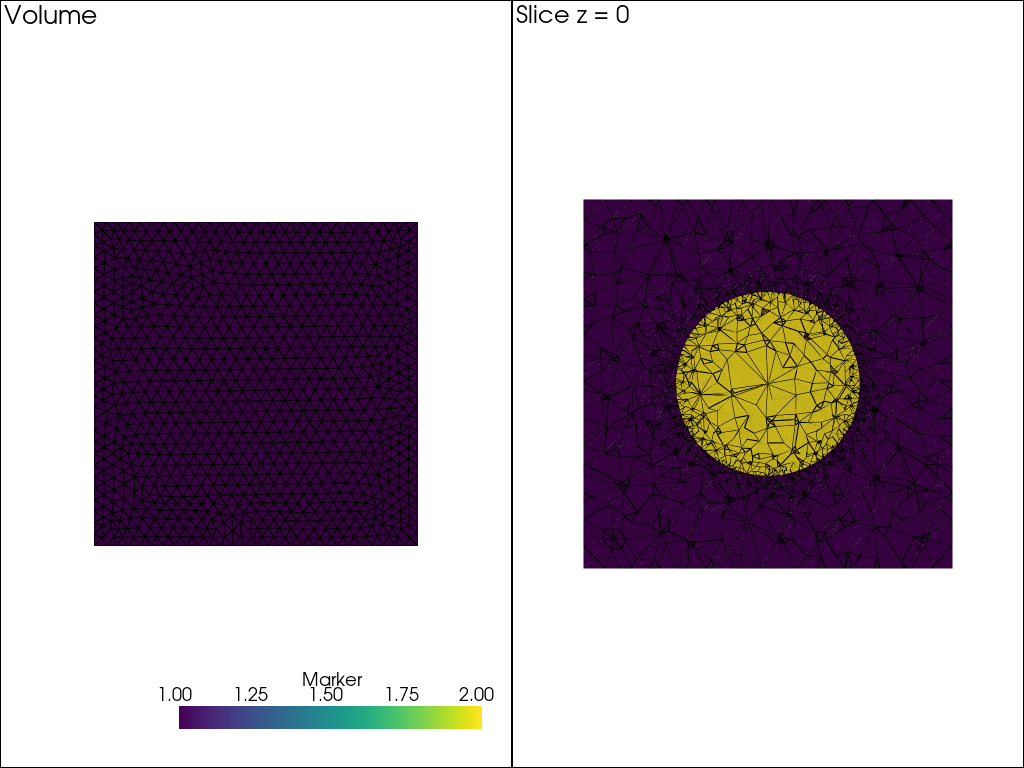

In [36]:
# ----------------------
# Pyvista visualization
# ----------------------
topology, cells, geometry = dolfinx.plot.vtk_mesh(domain)
function_grid = pyvista.UnstructuredGrid(topology, cells, geometry)
function_grid["Marker"] = cell_tags.values

slice_z0 = function_grid.slice(normal=(0, 0, 1), origin=(0, 0, 0))

vmin = function_grid["Marker"].min()
vmax = function_grid["Marker"].max()

plotter = pyvista.Plotter(shape=(1, 2))

# First view : volume
plotter.subplot(0, 0)
plotter.add_mesh(function_grid, scalars="Marker",
                 show_edges=True,
                 clim=[vmin, vmax])
plotter.view_xy()          
plotter.add_text("Volume", font_size=10)

# Second view : slice z = 0
plotter.subplot(0, 1)
plotter.add_mesh(slice_z0, scalars="Marker",
                 show_edges=True,
                 clim=[vmin, vmax])
plotter.view_xy()          
plotter.enable_parallel_projection()  
plotter.add_text("Slice z = 0", font_size=10)

plotter.show()

# Define integral over the different domains

In [37]:
dx = ufl.Measure("dx", domain=domain, subdomain_data=cell_tags)
ds = ufl.Measure("ds", domain=domain, subdomain_data=facet_tags)
one = dolfinx.fem.Constant(domain,dolfinx.default_scalar_type(1.))

In [38]:
# ------------------------------------------------------------------------
# Verification of the computation of the volumes of the different phases
# ------------------------------------------------------------------------

volume_domain = utils.assemble_scalar(dolfinx.fem.form(one * dx))

volume_matrix = utils.assemble_scalar(dolfinx.fem.form(one * dx(1)))
volume_pore = utils.assemble_scalar(dolfinx.fem.form(one * dx(2)))
volume_inclusion = utils.assemble_scalar(dolfinx.fem.form(one * dx(3)))

print("Volume matrix numerical :",volume_matrix)
print("Volume matrix theorical :",L-((4/3)*np.pi*R**3))

print("Volume pore numerical :",volume_pore)
print("Volume pore theorical :",(4/3)*np.pi*R**3)

Volume matrix numerical : 0.9345501704343062
Volume matrix theorical : 0.9345501530502126
Volume pore numerical : 0.06544982956569437
Volume pore theorical : 0.06544984694978735


# Define the damage problem

In [39]:
V = fem.functionspace(domain, ("Lagrange",mesh_order )) # ! Same order of interpolation of the test functions as for the mesh

# --------------------------------------------------------------------------------------------------
# Equivalent of "strain" and "stress" objects but for the damage problem (eps and sigma of dim 1x4)
# --------------------------------------------------------------------------------------------------
def eps(d):
    # eps = (grad(d), d)
    return ufl.as_vector((ufl.grad(d)[0], ufl.grad(d)[1], ufl.grad(d)[2], d))


def sigma(eps, A):
    # sigma = C.eps with C = Identity with A on the 4th component 
    return ufl.as_vector((eps[0], eps[1], eps[2], A*eps[3]))



# Trial and test function
d = ufl.TrialFunction(V)
d_bar = ufl.TestFunction(V)


# Bilinear form
bilinear_form_matrix = ufl.dot(sigma(eps(d), A_m), eps(d_bar))*dx(1)
bilinear_form_pore = ufl.dot(sigma(eps(d), A_p), eps(d_bar))*dx(2)

bilinear_form = bilinear_form_matrix + bilinear_form_pore


# Linear form
body_force_matrix = dolfinx.fem.Constant(domain, dolfinx.default_scalar_type((0,0,0,B_m)))
body_force_pore = dolfinx.fem.Constant(domain, dolfinx.default_scalar_type((0,0,0,B_p)))

linear_form_matrix = ufl.dot(body_force_matrix, eps(d_bar))*dx(1)
linear_form_pore = ufl.dot(body_force_pore, eps(d_bar))*dx(2)

linear_form = linear_form_matrix + linear_form_pore 

# Boundary conditions : https://bleyerj.github.io/comet-fenicsx/tours/homogenization/periodic_elasticity/periodic_elasticity.html

In [40]:
# Cartesian vectors
a1 = np.array([1,0,0])  # first vector generating periodicity
a2 = np.array([0,1,0])  # second vector generating periodicity
a3 = np.array([0,0,1])  # third vector generating periodicity

In [41]:
# Definition of faces
def right(x):
    return np.isclose(x[0], L) & np.logical_not(
        np.isclose(x[1], 0)
        | np.isclose(x[2], 0)
        | np.isclose(x[1], L)
        | np.isclose(x[2], L)
    )

def left(x):
    return np.isclose(x[0], 0) & np.logical_not(
        np.isclose(x[1], 0)
        | np.isclose(x[2], 0)
        | np.isclose(x[1], L)
        | np.isclose(x[2], L)
    )

def top(x):
    return np.isclose(x[1], L) & np.logical_not(
        np.isclose(x[0], 0)
        | np.isclose(x[2], 0)
        | np.isclose(x[0], L)
        | np.isclose(x[2], L)
    )

def bottom(x):
    return np.isclose(x[1], 0) & np.logical_not(
        np.isclose(x[0], 0)
        | np.isclose(x[2], 0)
        | np.isclose(x[0], L)
        | np.isclose(x[2], L)
    )

def front(x):
    return np.isclose(x[2], L) & np.logical_not(
        np.isclose(x[0], 0)
        | np.isclose(x[1], 0)
        | np.isclose(x[0], L)
        | np.isclose(x[1], L)
    )

def back(x):
    return np.isclose(x[2], 0) & np.logical_not(
        np.isclose(x[0], 0)
        | np.isclose(x[1], 0)
        | np.isclose(x[0], L)
        | np.isclose(x[1], L)
    )

# Definition of the edges of the upper face

def left_top_edge(x):
    return (
        np.isclose(x[0], 0)
        & np.isclose(x[1], L)
        & np.logical_not(np.isclose(x[2], 0) | np.isclose(x[2], L))
    )

def top_back_edge(x):
    return (
        np.isclose(x[1], L)
        & np.isclose(x[2], 0)
        & np.logical_not(np.isclose(x[0], 0) | np.isclose(x[0], L))
    )

def right_top_edge(x):
    return (
        np.isclose(x[0], L)
        & np.isclose(x[1], L)
        & np.logical_not(np.isclose(x[2], 0) | np.isclose(x[2], L))
    )

def top_front_edge(x):
    return (
        np.isclose(x[1], L)
        & np.isclose(x[2], L)
        & np.logical_not(np.isclose(x[0], 0) | np.isclose(x[0], L))
    )

# Definition of the edges of the lower face

def left_bottom_edge(x):
    return (
        np.isclose(x[0], 0)
        & np.isclose(x[1], 0)
        & np.logical_not(np.isclose(x[2], 0) | np.isclose(x[2], L))
    )

def bottom_back_edge(x):
    return (
        np.isclose(x[1], 0)
        & np.isclose(x[2], 0)
        & np.logical_not(np.isclose(x[0], 0) | np.isclose(x[0], L))
    )

def right_bottom_edge(x):
    return (
        np.isclose(x[0], L)
        & np.isclose(x[1], 0)
        & np.logical_not(np.isclose(x[2], 0) | np.isclose(x[2], L))
    )

def bottom_front_edge(x):
    return (
        np.isclose(x[1], 0)
        & np.isclose(x[2], L)
        & np.logical_not(np.isclose(x[0], 0) | np.isclose(x[0], L))
    )

# Definition of the edges of the front face

def left_front_edge(x):
    return (
        np.isclose(x[0], 0)
        & np.isclose(x[2], L)
        & np.logical_not(np.isclose(x[1], 0) | np.isclose(x[1], L))
    )

def right_front_edge(x):
    return (
        np.isclose(x[0], L)
        & np.isclose(x[2], L)
        & np.logical_not(np.isclose(x[1], 0) | np.isclose(x[1], L))
    )

# Definition of the edges of the back face

def left_back_edge(x):
    return (
        np.isclose(x[0], 0)
        & np.isclose(x[2], 0)
        & np.logical_not(np.isclose(x[1], 0) | np.isclose(x[1], L))
    )

def right_back_edge(x):
    return (
        np.isclose(x[0], L)
        & np.isclose(x[2], 0)
        & np.logical_not(np.isclose(x[1], 0) | np.isclose(x[1], L))
    )
        

In [42]:
# Periodic relation between faces

def periodic_relation_left_right(x):
    out_x = np.zeros(x.shape)
    out_x[0] = x[0] - L
    out_x[1] = x[1]
    out_x[2] = x[2]
    return out_x

def periodic_relation_bottom_top(x):
    out_x = np.zeros(x.shape)
    out_x[0] = x[0]
    out_x[1] = x[1] - L
    out_x[2] = x[2]
    return out_x

def periodic_relation_front_back(x):
    out_x = np.zeros(x.shape)
    out_x[0] = x[0]
    out_x[1] = x[1]
    out_x[2] = x[2] - L
    return out_x

# Periodic relation of the edges of the upper face

def periodic_relation_left_top_edge(x):
    out_x = np.zeros(x.shape)
    out_x[0] = x[0]
    out_x[1] = x[1] - L
    out_x[2] = x[2]
    return out_x

def periodic_relation_top_back_edge(x):
    out_x = np.zeros(x.shape)
    out_x[0] = x[0]
    out_x[1] = x[1] - L
    out_x[2] = x[2]
    return out_x

def periodic_relation_right_top_edge(x):
    out_x = np.zeros(x.shape)
    out_x[0] = x[0] - L
    out_x[1] = x[1] - L
    out_x[2] = x[2]
    return out_x

def periodic_relation_top_front_edge(x):
    out_x = np.zeros(x.shape)
    out_x[0] = x[0]
    out_x[1] = x[1] - L
    out_x[2] = x[2] - L
    return out_x

# Periodic relation of the edges of the lower face

def periodic_relation_right_bottom_edge(x):
    out_x = np.zeros(x.shape)
    out_x[0] = x[0] - L
    out_x[1] = x[1]
    out_x[2] = x[2]
    return out_x

def periodic_relation_bottom_front_edge(x):
    out_x = np.zeros(x.shape)
    out_x[0] = x[0]
    out_x[1] = x[1]
    out_x[2] = x[2] - L
    return out_x

# Periodic relation of the edges of the front face

def periodic_relation_left_front_edge(x):
    out_x = np.zeros(x.shape)
    out_x[0] = x[0]
    out_x[1] = x[1]
    out_x[2] = x[2] - L
    return out_x

def periodic_relation_right_front_edge(x):
    out_x = np.zeros(x.shape)
    out_x[0] = x[0] - L
    out_x[1] = x[1]
    out_x[2] = x[2] - L
    return out_x

# Periodic relation of the edges of the back face

def periodic_relation_right_back_edge(x):
    out_x = np.zeros(x.shape)
    out_x[0] = x[0] - L
    out_x[1] = x[1]
    out_x[2] = x[2]
    return out_x



bcs=[]

mpc = dolfinx_mpc.MultiPointConstraint(V)

# MPC between faces
mpc.create_periodic_constraint_geometrical(
    V, right, periodic_relation_left_right, bcs
)
mpc.create_periodic_constraint_geometrical(
    V, top, periodic_relation_bottom_top, bcs
)
mpc.create_periodic_constraint_geometrical(
    V, front, periodic_relation_front_back, bcs
)

# MPC edges upper face
mpc.create_periodic_constraint_geometrical(
    V, left_top_edge, periodic_relation_left_top_edge, bcs
)

mpc.create_periodic_constraint_geometrical(
    V, top_back_edge, periodic_relation_top_back_edge, bcs
)

mpc.create_periodic_constraint_geometrical(
    V, right_top_edge, periodic_relation_right_top_edge, bcs
)

mpc.create_periodic_constraint_geometrical(
    V, top_front_edge, periodic_relation_top_front_edge, bcs
)

# MPC edges lower face
mpc.create_periodic_constraint_geometrical(
    V, right_bottom_edge, periodic_relation_right_bottom_edge, bcs
)

mpc.create_periodic_constraint_geometrical(
    V, bottom_front_edge, periodic_relation_bottom_front_edge, bcs
)

# MPC edges front face
mpc.create_periodic_constraint_geometrical(
    V, left_front_edge, periodic_relation_left_front_edge, bcs
)

mpc.create_periodic_constraint_geometrical(
    V, right_front_edge, periodic_relation_right_front_edge, bcs
)

# MPC edges back face
mpc.create_periodic_constraint_geometrical(
    V, right_back_edge, periodic_relation_right_back_edge, bcs
)

mpc.finalize()

In [44]:
# -------------------------------------
# Final problem definition
# -------------------------------------
v = fem.Function(mpc.function_space, name="Periodic_fluctuation")
problem = LinearProblem(
    bilinear_form,
    linear_form,
    mpc,
    u=v,
    petsc_options={"ksp_type": "cg", "pc_type": "gamg"},
    #petsc_options={"ksp_type": "preonly", "pc_type": "lu"},
)

In [45]:
# --------------------------
# Solution computation
# --------------------------
d_solution = problem.solve()

In [46]:
# -----------------
# Paraview export
# -----------------
with dolfinx.io.XDMFFile(domain.comm, "damage_2phases.xdmf", "w") as file:
    file.write_mesh(domain)
    file.write_function(d_solution)

In [47]:
# ---------------------------
# L2-norm of the solution d
# ---------------------------
print("Norme L2 :", np.sqrt(utils.assemble_scalar(ufl.dot(d_solution, d_solution) * dx)))

Norme L2 : 0.11634498847035106
